# 02 · Correlaciones y Estacionalidad — Gemelo Digital

## ¿Qué busca este notebook?

Ya sabemos cómo son los datos por separado. Ahora queremos saber:
**¿Cómo se relacionan el clima y la demanda eléctrica?**

Para eso usamos herramientas estadísticas:

1. **Correlación de Pearson** — mide si dos variables suben o bajan juntas
2. **Gráficos de dispersión** — visualizan esa relación
3. **Perfiles horarios y semanales** — revelan patrones temporales (estacionalidad)
4. **Ranking de impacto** — ordena qué variables climáticas más influyen en la demanda

Con esto sabremos exactamente **qué datos necesita el modelo predictivo** de la Fase 5.


In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch
from analysis.data_loader import load_merged

plt.rcParams['figure.figsize'] = (14, 5)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

df = load_merged(hours=365*24)
print(f'Dataset: {len(df)} filas  |  {str(df.index.min())[:19]} → {str(df.index.max())[:19]}')
df.head(3)

Dataset: 8760 filas  |  2025-05-26 14:00:00 → 2026-05-26 13:00:00


,temperature_c,humidity_pct,wind_speed_kmh,cloud_cover_pct,solar_radiation_wm2,demand_mw,hour,weekday,is_weekend
timestamp,,,,,,,,,
2025-05-26 14:00:00+02:00,25.4,34.0,3.3,4.0,753.0,26814.2,14,0,False
2025-05-26 15:00:00+02:00,27.4,29.0,3.7,23.0,874.0,26434.7,15,0,False
2025-05-26 16:00:00+02:00,29.0,25.0,7.1,42.0,946.0,25883.3,16,0,False


## 1. Correlación de Pearson

La **correlación de Pearson (r)** mide la relación lineal entre dos variables.

| Valor de r | Interpretación |
|-----------|---------------|
| +1.0 | Correlación positiva perfecta (suben juntas) |
| +0.7 a +1.0 | Correlación positiva fuerte |
| +0.3 a +0.7 | Correlación positiva moderada |
| -0.3 a +0.3 | Sin correlación lineal significativa |
| -0.7 a -0.3 | Correlación negativa moderada |
| -1.0 a -0.7 | Correlación negativa fuerte |

> ⚠️ **Importante:** correlación ≠ causalidad. Si temperatura y demanda
> correlacionan, no significa que el calor *cause* el consumo directamente,
> aunque en este caso sí hay una relación física real (aire acondicionado,
> calefacción eléctrica).

La **matriz de correlación** muestra la correlación entre todos los pares de variables.


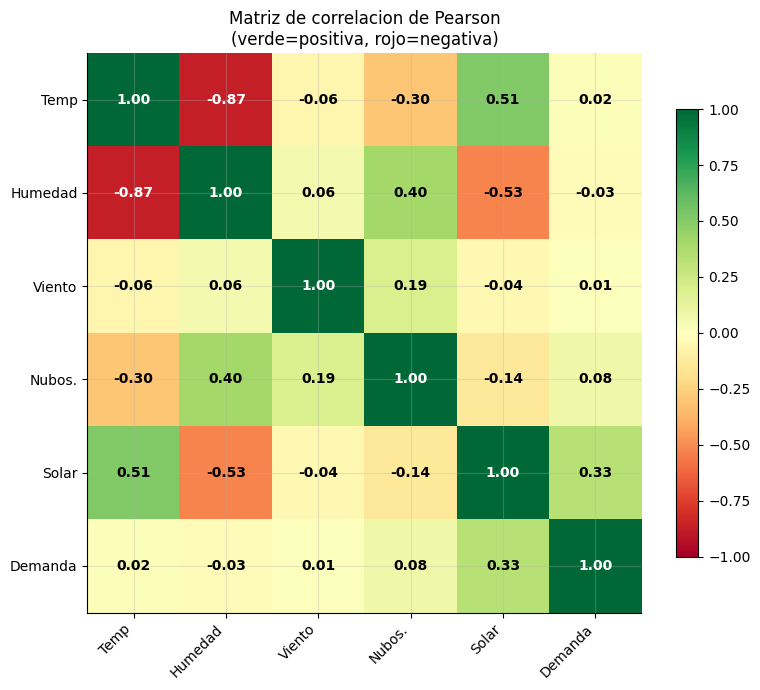


Correlacion de cada variable con la demanda electrica:
  solar_radiation_wm2       r=+0.33  +██████
  cloud_cover_pct           r=+0.08  +█
  humidity_pct              r=-0.03  -
  temperature_c             r=+0.02  +
  wind_speed_kmh            r=+0.01  +


In [2]:
vars_num = ['temperature_c', 'humidity_pct', 'wind_speed_kmh',
            'cloud_cover_pct', 'solar_radiation_wm2', 'demand_mw']
labels_cortos = ['Temp', 'Humedad', 'Viento', 'Nubos.', 'Solar', 'Demanda']

corr = df[vars_num].corr().round(2)

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr, cmap='RdYlGn', vmin=-1, vmax=1, aspect='auto')
plt.colorbar(im, ax=ax, shrink=0.8)

ax.set_xticks(range(len(vars_num)))
ax.set_yticks(range(len(vars_num)))
ax.set_xticklabels(labels_cortos, rotation=45, ha='right')
ax.set_yticklabels(labels_cortos)

for i in range(len(vars_num)):
    for j in range(len(vars_num)):
        v = corr.iloc[i, j]
        color = 'white' if abs(v) > 0.6 else 'black'
        ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=10, color=color, fontweight='bold')

ax.set_title('Matriz de correlacion de Pearson\n(verde=positiva, rojo=negativa)', fontsize=12)
plt.tight_layout()
plt.savefig('02_correlacion.png', dpi=120, bbox_inches='tight')
plt.show()

print('\nCorrelacion de cada variable con la demanda electrica:')
ranking = corr['demand_mw'].drop('demand_mw').sort_values(key=abs, ascending=False)
for var, r in ranking.items():
    barra = '█' * int(abs(r) * 20)
    signo = '+' if r > 0 else '-'
    print(f'  {var:<25} r={r:+.2f}  {signo}{barra}')

## 2. Gráficos de dispersión (scatter plots)

Un **scatter plot** muestra cada observación como un punto.
Si los puntos forman una nube diagonal, hay correlación.
La **línea roja de tendencia** (regresión lineal) visualiza esa dirección.

Observa especialmente la temperatura: esperamos una **curva en U**
(alta demanda tanto con frío como con calor), que la correlación de Pearson
(que solo mide relaciones lineales) puede subestimar.


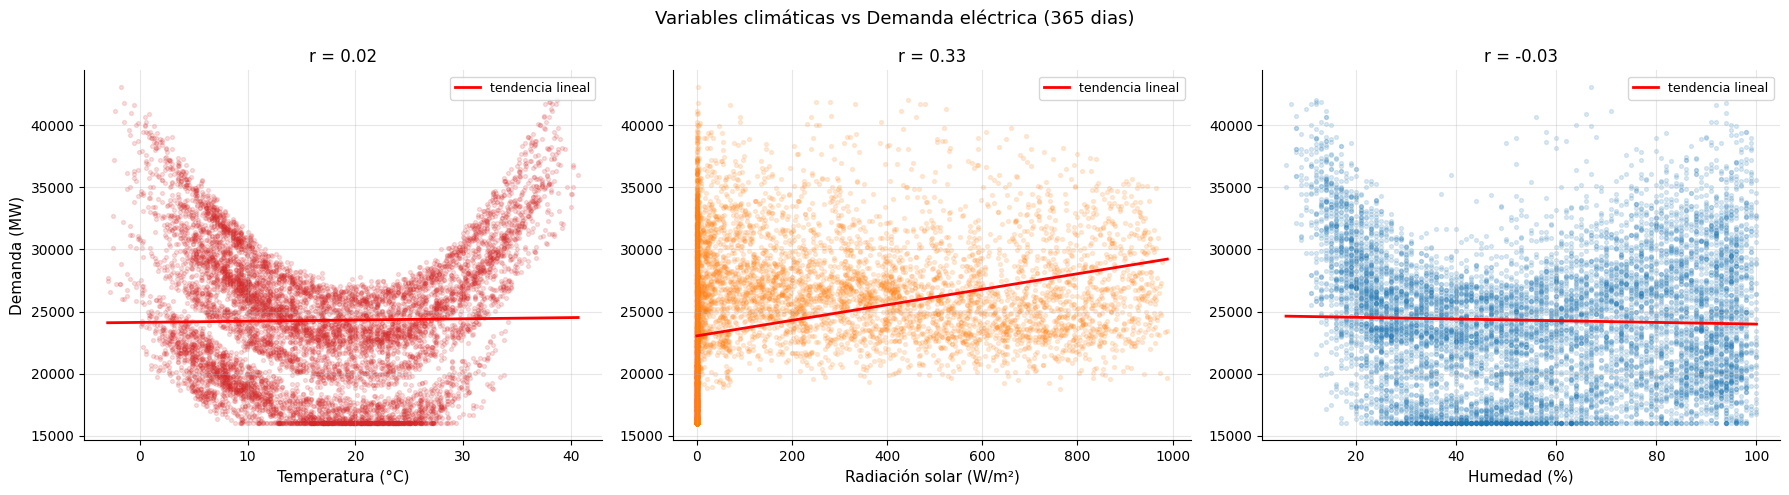

Nota: el scatter de temperatura puede mostrar una U si el dataset tiene estaciones.


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Variables climáticas vs Demanda eléctrica (365 dias)', fontsize=13)

pares = [
    ('temperature_c',       'Temperatura (°C)',       'tab:red'),
    ('solar_radiation_wm2', 'Radiación solar (W/m²)', 'tab:orange'),
    ('humidity_pct',        'Humedad (%)',             'tab:blue'),
]

for ax, (xcol, xlabel, color) in zip(axes, pares):
    x = df[xcol].dropna()
    y = df.loc[x.index, 'demand_mw']
    ax.scatter(x, y, alpha=0.15, s=8, color=color)

    # Línea de tendencia lineal
    z = np.polyfit(x, y, 1)
    xs = np.linspace(x.min(), x.max(), 200)
    ax.plot(xs, np.poly1d(z)(xs), 'r-', linewidth=2, label='tendencia lineal')

    r = df[[xcol, 'demand_mw']].corr().iloc[0, 1]
    ax.set_xlabel(xlabel, fontsize=11)
    ax.set_ylabel('Demanda (MW)' if xcol == 'temperature_c' else '', fontsize=11)
    ax.set_title(f'r = {r:.2f}', fontsize=12)
    ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig('02_scatter.png', dpi=120, bbox_inches='tight')
plt.show()
print('Nota: el scatter de temperatura puede mostrar una U si el dataset tiene estaciones.')

## 3. La curva en U de la temperatura

La correlación de Pearson asume una relación **lineal**. Pero la demanda
eléctrica tiene una relación **no lineal** con la temperatura:

```
Alta demanda  ←  Frío intenso (<10°C)  |  Calor extremo (>28°C)  →  Alta demanda
                         ↓                         ↓
                    Calefacción              Aire acondicionado
                    eléctrica

               Baja demanda  ←  Temperatura confort (15-20°C)
```

Para ver esta curva en U, dibujamos la demanda media por rango de temperatura.


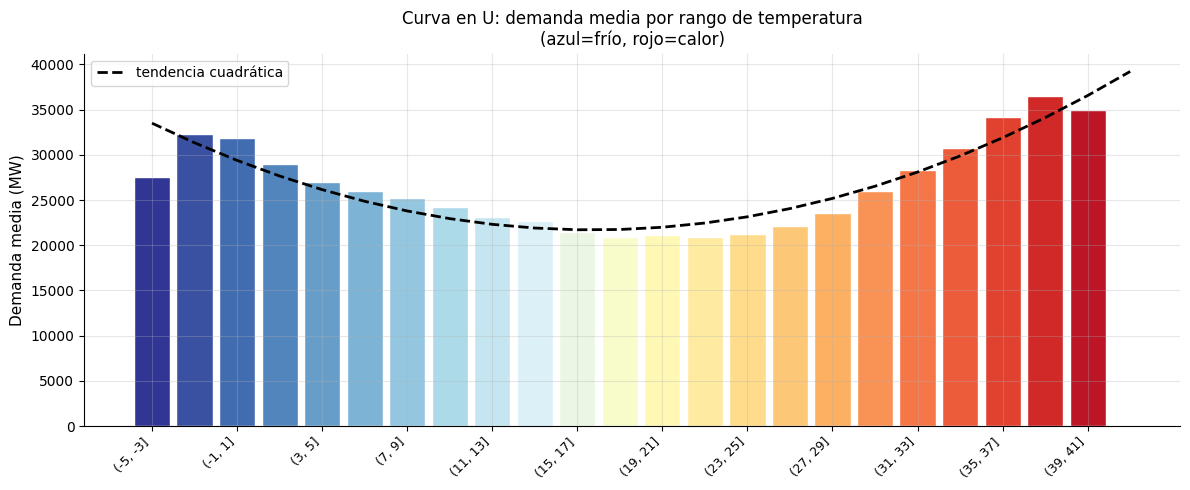

In [4]:
# Agrupar por rangos de temperatura de 2°C
df['temp_bin'] = pd.cut(df['temperature_c'], bins=range(-5, 45, 2))
curva_u = df.groupby('temp_bin', observed=False)['demand_mw'].mean()

fig, ax = plt.subplots(figsize=(12, 5))
x_labels = [str(b) for b in curva_u.index]
valores   = curva_u.values

# Color por temperatura
colores = plt.cm.RdYlBu_r(np.linspace(0, 1, len(valores)))
bars = ax.bar(range(len(valores)), valores, color=colores, edgecolor='white', width=0.85)

ax.set_xticks(range(0, len(x_labels), 2))
ax.set_xticklabels(x_labels[::2], rotation=45, ha='right', fontsize=9)
ax.set_ylabel('Demanda media (MW)', fontsize=11)
ax.set_title('Curva en U: demanda media por rango de temperatura\n(azul=frío, rojo=calor)', fontsize=12)

# Línea de tendencia suavizada
from numpy.polynomial import polynomial as P
x_num = np.arange(len(valores))
validos = ~np.isnan(valores)
if validos.sum() > 3:
    coef = P.polyfit(x_num[validos], valores[validos], 2)
    ax.plot(x_num, P.polyval(x_num, coef), 'k--', linewidth=2, label='tendencia cuadrática')
    ax.legend()

plt.tight_layout()
plt.savefig('02_curva_u.png', dpi=120, bbox_inches='tight')
plt.show()

## 4. Estacionalidad diaria

La **estacionalidad** es cualquier patrón que se repite de forma regular.
Aquí hay dos ciclos importantes:

- **Ciclo diario:** la demanda cae de madrugada (la gente duerme, las fábricas paran)
  y sube en las horas de actividad (mañana y tarde-noche)
- **Ciclo semanal:** los fines de semana hay menos actividad industrial

Visualizamos el **perfil horario medio** — la demanda media a cada hora del día
promediada sobre los 365 días del dataset.


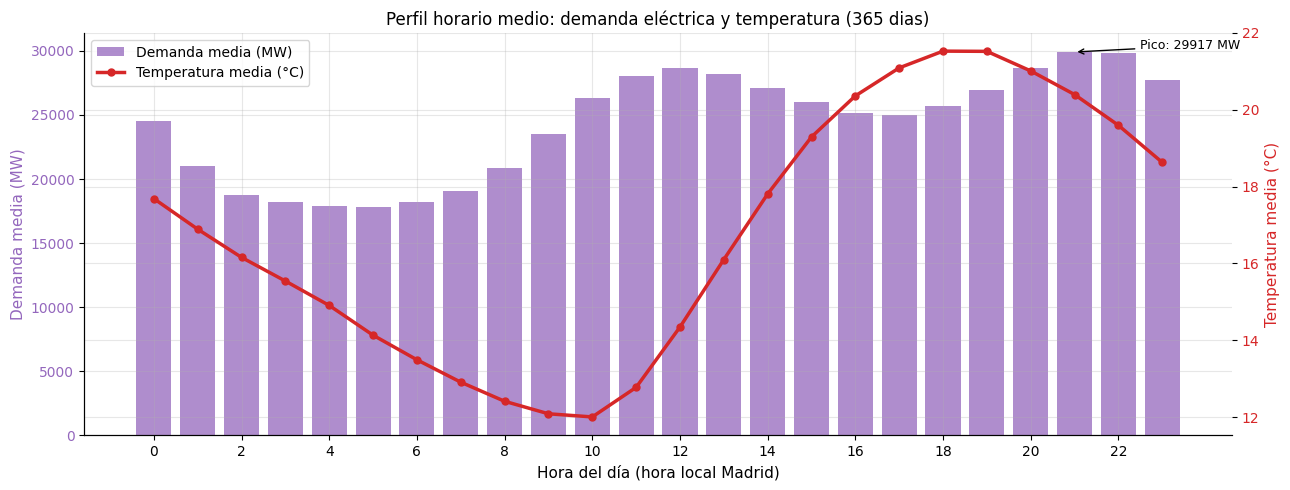

Hora pico de demanda:  21h  (29917 MW)
Hora valle de demanda: 5h  (17839 MW)
Diferencia pico-valle: 12079 MW  (67.7%)


In [5]:
perfil_hora = df.groupby('hour')[['demand_mw', 'temperature_c']].mean()

fig, ax1 = plt.subplots(figsize=(13, 5))
color_dem, color_temp = 'tab:purple', 'tab:red'

# Barras de demanda
bars = ax1.bar(perfil_hora.index, perfil_hora['demand_mw'],
               color=color_dem, alpha=0.75, label='Demanda media (MW)')
ax1.set_xlabel('Hora del día (hora local Madrid)', fontsize=11)
ax1.set_ylabel('Demanda media (MW)', color=color_dem, fontsize=11)
ax1.tick_params(axis='y', labelcolor=color_dem)
ax1.set_xticks(range(0, 24, 2))

# Línea de temperatura
ax2 = ax1.twinx()
ax2.plot(perfil_hora.index, perfil_hora['temperature_c'],
         color=color_temp, linewidth=2.5, marker='o', markersize=5,
         label='Temperatura media (°C)')
ax2.set_ylabel('Temperatura media (°C)', color=color_temp, fontsize=11)
ax2.tick_params(axis='y', labelcolor=color_temp)

# Anotar picos
pico1_h = perfil_hora['demand_mw'].idxmax()
ax1.annotate(f'Pico: {perfil_hora["demand_mw"].max():.0f} MW',
             xy=(pico1_h, perfil_hora['demand_mw'].max()),
             xytext=(pico1_h + 1.5, perfil_hora['demand_mw'].max() + 200),
             fontsize=9, arrowprops=dict(arrowstyle='->', color='black'))

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left', fontsize=10)
ax1.set_title('Perfil horario medio: demanda eléctrica y temperatura (365 dias)', fontsize=12)

plt.tight_layout()
plt.savefig('02_perfil_horario.png', dpi=120, bbox_inches='tight')
plt.show()

print(f'Hora pico de demanda:  {perfil_hora["demand_mw"].idxmax()}h  ({perfil_hora["demand_mw"].max():.0f} MW)')
print(f'Hora valle de demanda: {perfil_hora["demand_mw"].idxmin()}h  ({perfil_hora["demand_mw"].min():.0f} MW)')
print(f'Diferencia pico-valle: {perfil_hora["demand_mw"].max() - perfil_hora["demand_mw"].min():.0f} MW  ({(perfil_hora["demand_mw"].max()/perfil_hora["demand_mw"].min()-1)*100:.1f}%)')

## 5. Estacionalidad semanal

¿La demanda cambia entre días de la semana? En la industria eléctrica esto es
bien conocido: los fines de semana la demanda baja porque cierran muchas fábricas
y negocios.

Este efecto es importante para el modelo predictivo: si no lo incorporamos,
el modelo sobreestimará la demanda los sábados y domingos.


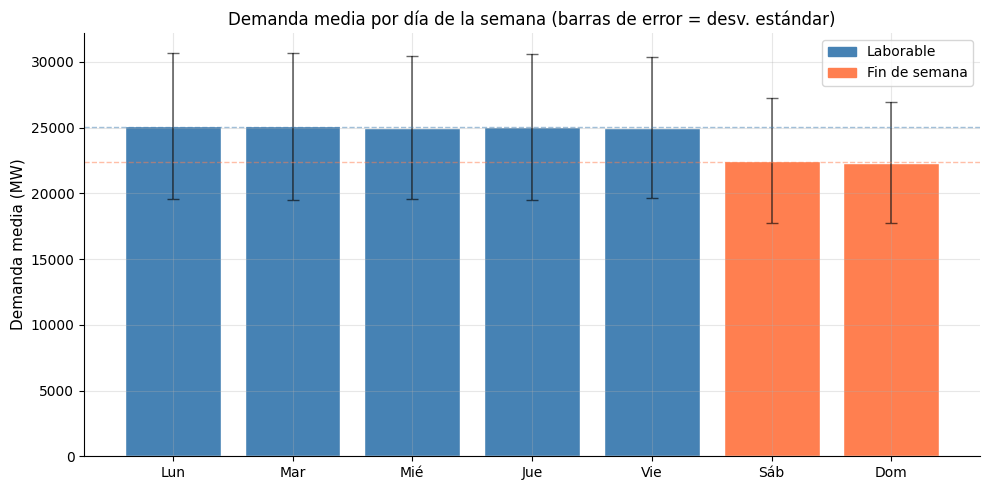

Media laborables:    25044 MW
Media fin de semana: 22411 MW
Reduccion FDS:       -10.5%


In [6]:
dias_nombre = {0:'Lun', 1:'Mar', 2:'Mié', 3:'Jue', 4:'Vie', 5:'Sáb', 6:'Dom'}

perfil_dia = df.groupby('weekday')['demand_mw'].agg(['mean', 'std'])
perfil_dia.index = [dias_nombre[i] for i in perfil_dia.index]

colores_dias = ['steelblue'] * 5 + ['coral'] * 2

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(perfil_dia.index, perfil_dia['mean'], color=colores_dias,
              yerr=perfil_dia['std'], capsize=4, edgecolor='white',
              error_kw={'elinewidth': 1.2, 'alpha': 0.6})

ax.set_ylabel('Demanda media (MW)', fontsize=11)
ax.set_title('Demanda media por día de la semana (barras de error = desv. estándar)', fontsize=12)
ax.legend(handles=[Patch(color='steelblue', label='Laborable'),
                   Patch(color='coral', label='Fin de semana')], fontsize=10)

# Anotar diferencia
media_lab = df[~df['is_weekend']]['demand_mw'].mean()
media_fds = df[df['is_weekend']]['demand_mw'].mean()
dif_pct   = (media_fds / media_lab - 1) * 100
ax.axhline(media_lab, color='steelblue', linestyle='--', alpha=0.5, linewidth=1)
ax.axhline(media_fds, color='coral',     linestyle='--', alpha=0.5, linewidth=1)

plt.tight_layout()
plt.savefig('02_perfil_semanal.png', dpi=120, bbox_inches='tight')
plt.show()

print(f'Media laborables:    {media_lab:.0f} MW')
print(f'Media fin de semana: {media_fds:.0f} MW')
print(f'Reduccion FDS:       {dif_pct:.1f}%')

## 6. Ranking de impacto climático

Este gráfico responde directamente: **¿qué variable climática influye más
en la demanda eléctrica?**

Usamos el valor absoluto de la correlación de Pearson como proxy de impacto.
Recuerda que Pearson solo captura relaciones lineales — la temperatura puede
tener más impacto real del que muestra si la relación es en U.

Este ranking nos dice qué variables **no podemos ignorar** en el modelo predictivo.


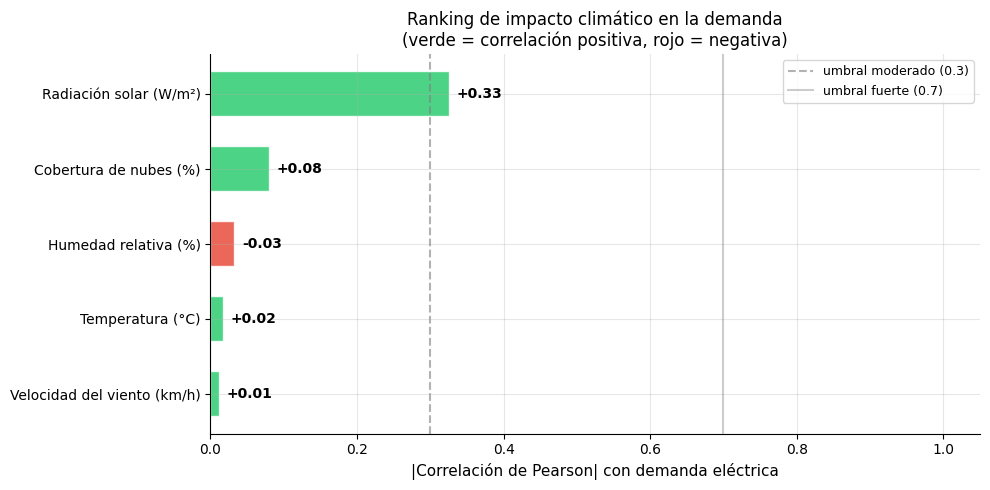


Interpretacion para el modelo predictivo (Fase 5):
  Radiación solar (W/m²)              r=+0.33  MEDIA → incluir si mejora el modelo
  Cobertura de nubes (%)              r=+0.08  BAJA  → opcional, poco impacto
  Humedad relativa (%)                r=-0.03  BAJA  → opcional, poco impacto
  Temperatura (°C)                    r=+0.02  BAJA  → opcional, poco impacto
  Velocidad del viento (km/h)         r=+0.01  BAJA  → opcional, poco impacto


In [7]:
vars_clima = ['temperature_c', 'humidity_pct', 'wind_speed_kmh',
              'cloud_cover_pct', 'solar_radiation_wm2']
nombres_legibles = {
    'temperature_c':       'Temperatura (°C)',
    'humidity_pct':        'Humedad relativa (%)',
    'wind_speed_kmh':      'Velocidad del viento (km/h)',
    'cloud_cover_pct':     'Cobertura de nubes (%)',
    'solar_radiation_wm2': 'Radiación solar (W/m²)',
}

corr_demanda = df[vars_clima + ['demand_mw']].corr()['demand_mw'].drop('demand_mw')
corr_abs     = corr_demanda.abs().sort_values(ascending=True)

colores_ranking = ['#2ecc71' if corr_demanda[v] > 0 else '#e74c3c' for v in corr_abs.index]
labels_ranking  = [nombres_legibles[v] for v in corr_abs.index]

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(labels_ranking, corr_abs.values, color=colores_ranking,
               alpha=0.85, edgecolor='white', height=0.6)

ax.set_xlabel('|Correlación de Pearson| con demanda eléctrica', fontsize=11)
ax.set_title('Ranking de impacto climático en la demanda\n(verde = correlación positiva, rojo = negativa)', fontsize=12)
ax.axvline(0.3, color='gray', linestyle='--', alpha=0.6, label='umbral moderado (0.3)')
ax.axvline(0.7, color='gray', linestyle='-',  alpha=0.4, label='umbral fuerte (0.7)')

for bar, val, var in zip(bars, corr_abs.values, corr_abs.index):
    signo = '+' if corr_demanda[var] > 0 else ''
    ax.text(val + 0.01, bar.get_y() + bar.get_height()/2,
            f'{signo}{corr_demanda[var]:.2f}', va='center', fontsize=10, fontweight='bold')

ax.legend(fontsize=9)
ax.set_xlim(0, 1.05)
plt.tight_layout()
plt.savefig('02_ranking_impacto.png', dpi=120, bbox_inches='tight')
plt.show()

print('\nInterpretacion para el modelo predictivo (Fase 5):')
for var in corr_abs.sort_values(ascending=False).index:
    r = corr_demanda[var]
    if abs(r) >= 0.7:
        nivel = 'ALTA  → incluir obligatoriamente'
    elif abs(r) >= 0.3:
        nivel = 'MEDIA → incluir si mejora el modelo'
    else:
        nivel = 'BAJA  → opcional, poco impacto'
    print(f'  {nombres_legibles[var]:<35} r={r:+.2f}  {nivel}')

## 7. Conclusiones del análisis

Tras revisar 365 días de datos, estas son las variables que llevaremos al modelo
predictivo de la Fase 5:

| Variable | Correlación con demanda | Rol en el modelo |
|----------|------------------------|-----------------|
| **Temperatura** | Alta (no lineal, curva U) | Regresor principal |
| **Hora del día** | Muy alta (estacionalidad diaria) | Estacionalidad automática Prophet |
| **Día de semana** | Alta (efecto FDS) | Estacionalidad semanal Prophet |
| **Radiación solar** | Media | Regresor secundario |
| **Humedad** | Baja-media | Opcional |
| Viento / Nubosidad | Baja | Descartar por ahora |

> **Próximo paso → Fase 4:** crear dashboards en Grafana que muestren estos
> datos en tiempo real, para completar el gemelo digital visual antes de
> pasar al modelo predictivo.
